# Multimeter: R_eff(i, j) Between Arbitrary Nodes


## Before you start (read this first)

**On Google Colab:** the plots and text you see already in this notebook are
saved from a *previous* run (mine, while building it); they do **not**
mean the variables exist in *your* browser session. Colab always starts you
with an empty runtime. If you jump straight to a cell in the middle and run
just that one, you'll get an error like `NameError: name 'intersections' is
not defined`, and since the cell crashed before making a new plot, the old
picture just stays there looking unchanged.

**If a cell suddenly errors with `TypeError: ... got an unexpected keyword argument ...` after working before:** that means the code in `utils/` changed since you started this session, and Python is still using the old version it already loaded. Re-run the imports cell in Section 1 (it force-reloads the changed files), then re-run the cell that failed. If that doesn't fix it, `Runtime` -> `Restart runtime` and `Run all` again.\n\n**So, once, top to bottom:** `Runtime` menu -> `Run all` (or `Ctrl+F9` /
`Cmd+F9`). That takes a minute (it generates a random network, runs several
checks). After that finishes, everything below is live in your session.

**Then, to test your own node pairs:** scroll to **Section 5 (the
interactive probe)**, change the `node_i` / `node_j` numbers in that one
cell, and re-run *only that cell* (click it, press `Shift+Enter`). You can
repeat this as many times as you want; no need to run anything else again,
as long as you don't restart the runtime.

**What each section actually does, in plain terms:**
| Section | What it's doing | Why |
|---|---|---|
| 1 | Imports the code | Just loading tools, nothing to understand yet |
| 2 | Tests the tool on two tiny hand-made circuits where we already know the answer | Proves the resistance calculation itself is correct, before trusting it on a real network |
| 3 | Generates one random percolating network | This is the "circuit" everything else probes |
| 4 | Draws that network with every node numbered | So you can pick two numbers to probe |
| **5** | **The multimeter**: you choose two node numbers, it tells you the resistance between them | This is the main feature you asked for |
| 6 | A protocol for picking many `j` nodes automatically, at increasing distance from one fixed node, instead of you choosing by hand every time | To see how resistance grows with distance across the whole network |
| 7 | Repeats section 6 on 5 different random networks | Checks the trend from section 6 isn't a fluke of one particular network |
| 8 | Compares one point-to-point measurement against the "merge the whole edge into one terminal" measurement used elsewhere in the project | Sanity check: touching two single points should read *more* resistance than merging whole regions together |

---
## 1. Setup and imports

In [1]:
# Environment and path setup is handled in the next cell.

In [2]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")

Mounted at /content/drive
Environment: Google Colab
Utils path: /content/drive/MyDrive/ColabProject/utils


In [3]:
import importlib
import multimeter as multimeter_module
import network_visualization as network_visualization_module
import pipeline_utils as pipeline_utils_module
import laplacian_utils as laplacian_utils_module

# Force a fresh reload of the utils/*.py files this notebook depends on,
# so re-running just this cell (instead of a full Runtime -> Restart) picks
# up any code changes made to them since this session started. Plain
# `import` only runs a module's code once per session; without this,
# re-running a cell after a file changes still uses the OLD version already
# cached in memory, and calling a newly added function/argument fails with
# a confusing TypeError.
importlib.reload(multimeter_module)
importlib.reload(network_visualization_module)
importlib.reload(pipeline_utils_module)
importlib.reload(laplacian_utils_module)

from pipeline_utils import generate_percolating_network
from multimeter import measure_r_eff, onion_layers, run_onion_protocol, run_onion_protocol_pinv
from laplacian_utils import effective_resistance_from_reference
from network_visualization import plot_network_colored_by_voltage, plot_r_eff_vs_distance
from experiment_manager import setup_experiment
import ipywidgets as widgets
from IPython.display import display, clear_output

exp_manager = setup_experiment()


EXPERIMENT CONFIGURATION
  Environment: Google Colab
  Experiment #: 841
  Timestamp: 20260825_120642
  Results directory: /content/drive/MyDrive/ColabProject/experiments/exp_841



In [4]:
def build_graph_from_segments(n_nodes, segment_to_nodes):
    """ImpedanceCalculator's constructor expects a `graph` list, but
    measure_r_eff's two-point solve never actually reads it; this just
    builds one of the right shape from segment_to_nodes, the same way
    path_analysis.rebuild_local_graph does."""
    g = [[] for _ in range(n_nodes)]
    for e, (n1, n2) in segment_to_nodes.items():
        g[n1].append(e)
        g[n2].append(e)
    return g

---
## 2. Sanity check: validate against known closed-form networks

Two hand-built networks where R_eff can be computed by hand, so a mismatch
here would mean the multimeter itself is broken before it ever touches a
real percolating network.

In [5]:
print("="*70)
print("4-node ring, unit resistors (k=1)")
print("="*70)

ring_intersections = [[0.0, 0.5], [0.5, 1.0], [1.0, 0.5], [0.5, 0.0]]
ring_segment_to_nodes = {0: (0, 1), 1: (1, 2), 2: (2, 3), 3: (3, 0)}
ring_graph = build_graph_from_segments(len(ring_intersections), ring_segment_to_nodes)

r_opposite = measure_r_eff(ring_intersections, ring_graph, ring_segment_to_nodes, 0, 2, k=1.0)
r_adjacent = measure_r_eff(ring_intersections, ring_graph, ring_segment_to_nodes, 0, 1, k=1.0)

print(f"R_eff(0,2) opposite nodes = {r_opposite['impedance']:.4f}  (expected 1.0000, two arcs of 2 in parallel)")
print(f"R_eff(0,1) adjacent nodes = {r_adjacent['impedance']:.4f}  (expected 0.7500, 1 || 3)")
assert abs(r_opposite['impedance'] - 1.0) < 1e-9
assert abs(r_adjacent['impedance'] - 0.75) < 1e-9
print("PASSED")

4-node ring, unit resistors (k=1)
R_eff(0,2) opposite nodes = 1.0000  (expected 1.0000, two arcs of 2 in parallel)
R_eff(0,1) adjacent nodes = 0.7500  (expected 0.7500, 1 || 3)
PASSED


In [6]:
print("="*70)
print("10-node resistor ladder (series), unit resistors")
print("="*70)

ladder_intersections = [[0.1 * i, 0.0] for i in range(10)]
ladder_segment_to_nodes = {i: (i, i + 1) for i in range(9)}
ladder_graph = build_graph_from_segments(len(ladder_intersections), ladder_segment_to_nodes)

all_passed = True
for n in range(1, 10):
    r = measure_r_eff(ladder_intersections, ladder_graph, ladder_segment_to_nodes, 0, n, k=1.0)
    ok = abs(r['impedance'] - n) < 1e-9
    all_passed &= ok
    print(f"R_eff(0,{n}) = {r['impedance']:.4f}  (expected {n}, {'OK' if ok else 'MISMATCH'})")

print("PASSED" if all_passed else "FAILED")

10-node resistor ladder (series), unit resistors
R_eff(0,1) = 1.0000  (expected 1, OK)
R_eff(0,2) = 2.0000  (expected 2, OK)
R_eff(0,3) = 3.0000  (expected 3, OK)
R_eff(0,4) = 4.0000  (expected 4, OK)
R_eff(0,5) = 5.0000  (expected 5, OK)
R_eff(0,6) = 6.0000  (expected 6, OK)
R_eff(0,7) = 7.0000  (expected 7, OK)
R_eff(0,8) = 8.0000  (expected 8, OK)
R_eff(0,9) = 9.0000  (expected 9, OK)
PASSED


---
## 3. Generate a percolating network

Any percolating network works here. To probe a network from a previously
saved experiment instead of generating a fresh one, load it with
`experiment_manager.load_network(N)` and run it through
`pipeline_utils.run_full_pipeline` the way `test_random_network_impedance.ipynb`
does, then use its `pre_merge_intersections` / `pre_merge_segment_to_nodes`
below in place of `intersections` / `segment_to_nodes`.

In [7]:
N, a, k = 40, 0.6, 1000.0
results, attempts = generate_percolating_network(N, a, k_uniform=k, seed=11)

intersections = results['pre_merge_intersections']
segment_to_nodes = results['pre_merge_segment_to_nodes']
graph = build_graph_from_segments(len(intersections), segment_to_nodes)
source_nodes = results['pre_merge_source_nodes']
drain_nodes = results['pre_merge_drain_nodes']

print(f"Percolating network found after {attempts} attempt(s)")
print(f"  Nodes: {len(intersections)}   Edges: {len(segment_to_nodes)}")
print(f"  Whole-face source-drain R_eff: {results['impedance']:.4f} Ohm")

Percolating network found after 2 attempt(s)
  Nodes: 249   Edges: 458
  Whole-face source-drain R_eff: 2758.7057 Ohm


---
## 4. Node IDs, for manually picking probes

Every scatter point below is annotated with its node index: pick any two for the interactive probe in the next section.

  [OK] Figure saved: node_ids.png


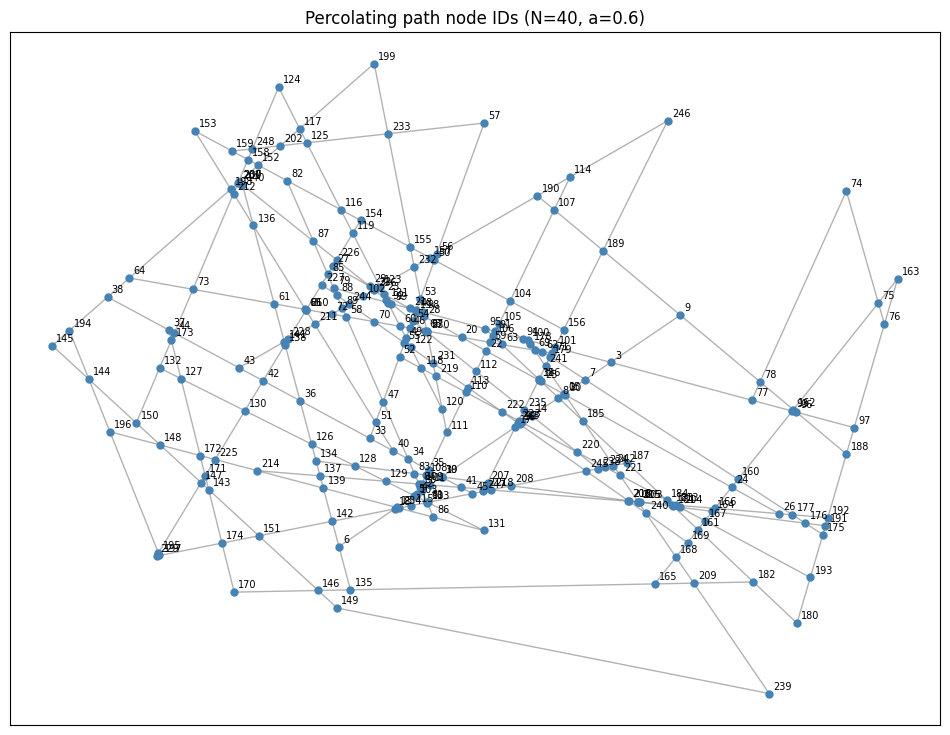

In [8]:
fig, ax = plt.subplots(figsize=(12, 9))
for n1, n2 in segment_to_nodes.values():
    x = [intersections[n1][0], intersections[n2][0]]
    y = [intersections[n1][1], intersections[n2][1]]
    ax.plot(x, y, color='gray', alpha=0.6, linewidth=1, zorder=1)
for i, (x, y) in enumerate(intersections):
    ax.scatter(x, y, c='steelblue', s=25, zorder=2)
    ax.annotate(str(i), (x, y), textcoords="offset points", xytext=(3, 3), fontsize=7)
ax.set_title(f'Percolating path node IDs (N={N}, a={a})')
ax.set_xticks([])
ax.set_yticks([])
exp_manager.save_figure(fig, 'node_ids.png')
plt.show()

---
## 5. Interactive probe: pick two nodes with the widget below

This is the multimeter itself. Run the cell below **once**: it draws two
number boxes and a **Measure** button. After that, you never have to touch
code or re-run anything: just type two different node numbers (from the
plot in Section 4 above, between 0 and the total node count shown) into the
boxes and click **Measure**. The result and a new highlighted plot appear
right below the button, and you can click Measure again as many times as
you want with new numbers.

The two boxes are capped to valid node IDs for this network, so you can't
type a number that's out of range. If you pick two nodes that aren't
connected anywhere in the network, `R_eff` will show `inf` (infinite
resistance), which is the correct answer, not a bug: no current can flow
between them.

*(If you get an error mentioning a name is not defined when you run the
cell, you haven't run the setup cells in this browser session yet: see
"Before you start" at the top of this notebook, Runtime -> Run all, once.)*

In [9]:
# Make sure Section 3 (network generation) has actually run in THIS session.
try:
    intersections
except NameError:
    raise RuntimeError(
        "The network variables (intersections, graph, segment_to_nodes, k, "
        "source_nodes, drain_nodes) don't exist yet in this Colab session. "
        "Run 'Runtime -> Run all' once (top to bottom), THEN come back and "
        "re-run just this cell."
    )

max_node_id = len(intersections) - 1

node_i_box = widgets.BoundedIntText(
    value=source_nodes[0], min=0, max=max_node_id, description="node_i:",
    style={'description_width': 'initial'},
)
node_j_box = widgets.BoundedIntText(
    value=drain_nodes[0], min=0, max=max_node_id, description="node_j:",
    style={'description_width': 'initial'},
)
measure_button = widgets.Button(description="Measure", button_style="primary", icon="bolt")
probe_output = widgets.Output()


def on_measure_clicked(_):
    with probe_output:
        clear_output(wait=True)
        node_i = node_i_box.value
        node_j = node_j_box.value

        if node_i == node_j:
            print(f"node_i and node_j are both {node_i}: pick two different node numbers.")
            return

        # Probe: solve the circuit with node_i held at 1V and node_j at 0V,
        # with everything else floating. This is exactly what measure_r_eff
        # does internally.
        probe = measure_r_eff(intersections, graph, segment_to_nodes, node_i, node_j, k=k)

        print(f"R_eff({node_i}, {node_j}) = {probe['impedance']:.4f} Ohm")
        print(f"Euclidean distance between probes: {probe['probe_distance']:.4f}")

        fig = plot_network_colored_by_voltage(
            intersections, segment_to_nodes, probe['voltages'],
            terminal_nodes=[node_i, node_j],
            terminal_currents={node_i: -probe['I_total'], node_j: probe['I_total']},
            title=f"Multimeter probe: R_eff({node_i}, {node_j}) = {probe['impedance']:.4f} Ω",
            show_node_ids=True, figsize=(12, 9),
        )
        plt.show()


measure_button.on_click(on_measure_clicked)

print(f"Valid node IDs for this network: 0 to {max_node_id}")
display(widgets.HBox([node_i_box, node_j_box, measure_button]), probe_output)

# Show one measurement immediately so the cell isn't blank before your first click.
on_measure_clicked(None)

Valid node IDs for this network: 0 to 248


Output()

A few more preset pairs, for comparison (edit these too, or just use section 5 above):

In [10]:
manual_pairs = {
    'source corner -> drain corner': (source_nodes[0], drain_nodes[-1]),
    'two source-face nodes': (source_nodes[0], source_nodes[-1]) if len(source_nodes) > 1 else None,
    'two drain-face nodes': (drain_nodes[0], drain_nodes[-1]) if len(drain_nodes) > 1 else None,
}
manual_pairs = {label: pair for label, pair in manual_pairs.items() if pair is not None and pair[0] != pair[1]}

exp2_records = []
for label, (i, j) in manual_pairs.items():
    r = measure_r_eff(intersections, graph, segment_to_nodes, i, j, k=k)
    print(f"[{label}] R_eff({i},{j}) = {r['impedance']:.4f} Ohm  (probe distance = {r['probe_distance']:.4f})")
    exp2_records.append({'label': label, 'node_i': i, 'node_j': j,
                         'r_eff': r['impedance'], 'probe_distance': r['probe_distance']})

[source corner -> drain corner] R_eff(145,163) = 3617.5282 Ohm  (probe distance = 0.8704)
[two source-face nodes] R_eff(145,194) = 638.3481 Ohm  (probe distance = 0.0279)
[two drain-face nodes] R_eff(75,163) = 634.4672 Ohm  (probe distance = 0.0403)


---
## 6. Onion-layer protocol: R_eff vs. distance

Probing every node pair is wasteful; instead fix one `reference_node` and
probe outward through concentric distance shells. `onion_layers` first shows
which nodes fall in each shell:

In [11]:
reference_node = source_nodes[0]
layer_distances = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

layers = onion_layers(intersections, reference_node, layer_distances=layer_distances)
for d, candidates in layers.items():
    print(f"  d={d:.1f}: {len(candidates)} candidate node(s)")

  d=0.1: 10 candidate node(s)
  d=0.2: 13 candidate node(s)
  d=0.3: 51 candidate node(s)
  d=0.4: 71 candidate node(s)
  d=0.5: 47 candidate node(s)
  d=0.6: 17 candidate node(s)
  d=0.7: 19 candidate node(s)
  d=0.8: 15 candidate node(s)
  d=0.9: 4 candidate node(s)


`run_onion_protocol` then probes R_eff(reference_node, j) for j in each
non-empty shell (capped at `max_probes_per_layer` per shell, randomly
sampled with `seed` for reproducibility if a shell is crowded).

Note that `i` is fixed at `reference_node` for every single probe below:
the result is N distinct `(reference_node, j)` pairs, one per `j`, not N
arbitrary pairs picked from anywhere in the network. That is the point of
the protocol: it studies how R_eff grows with distance from one fixed
point, instead of measuring the full O(n^2) space of all possible pairs.

In [12]:
records = run_onion_protocol(
    intersections, graph, segment_to_nodes, reference_node,
    layer_distances=layer_distances, k=k,
    max_probes_per_layer=15, seed=0, verbose=True
)

distinct_j = len(set(r['node_j'] for r in records))
print(f"\nTotal probes measured: {len(records)}")
print(f"i is fixed at node {reference_node} for every probe.")
print(f"j takes {distinct_j} distinct value(s), one per probe (no repeats across layers).")

  layer d=0.1: probing 10/10 candidate node(s)
  layer d=0.2: probing 13/13 candidate node(s)
  layer d=0.3: probing 15/51 candidate node(s)
  layer d=0.4: probing 15/71 candidate node(s)
  layer d=0.5: probing 15/47 candidate node(s)
  layer d=0.6: probing 15/17 candidate node(s)
  layer d=0.7: probing 15/19 candidate node(s)
  layer d=0.8: probing 15/15 candidate node(s)
  layer d=0.9: probing 4/4 candidate node(s)

Total probes measured: 117
i is fixed at node 145 for every probe.
j takes 117 distinct value(s), one per probe (no repeats across layers).


  [OK] Figure saved: r_eff_vs_distance.png


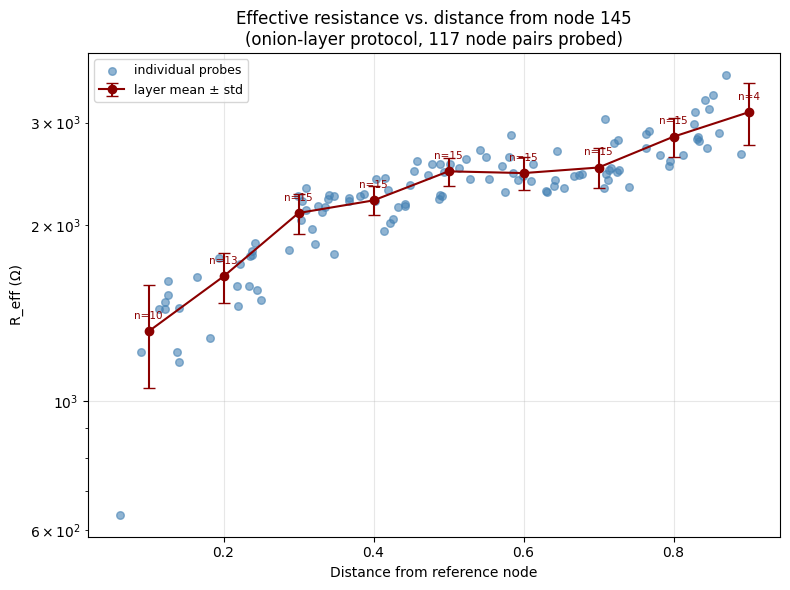

In [13]:
fig = plot_r_eff_vs_distance(records, reference_node=reference_node)
exp_manager.save_figure(fig, 'r_eff_vs_distance.png')
plt.show()

Each blue dot is one `measure_r_eff(reference_node, j)` probe; the red line
is the per-layer mean ± std, since several `j` nodes usually qualify for the
same shell. All 117-style probe counts above come from a single fixed `i`
(the `reference_node`): only `j` changes from point to point, which is why
the plot title says "N node pairs probed" rather than showing every pair
explicitly.

---
## 6b. Validating the pinv fast path

`run_onion_protocol` above did 117 separate dense linear solves (one per probe) to build this one
curve. That's fine for a single curve, but the planned large `(N, a, d)` grid sweep needs a mean
onion curve for *hundreds* of `(N, a, d)` triples, each averaged over several network
realizations -- doing a fresh solve per probe would multiply out fast.

`run_onion_protocol_pinv` (in `multimeter.py`, backed by
`laplacian_utils.effective_resistance_from_reference`) computes the Laplacian pseudoinverse
**once** per network and reads off R_eff to every node from it -- same total cost as a single
solve, regardless of how many nodes get probed. It only supports the distance-dependent
resistance model (`R_edge = R0 * edge_length`, the model the grid sweep uses), not the uniform-`k`
model used in Sections 5-8 above, so the comparison below reruns the onion protocol on the *same*
network with `distance_dependent=True` instead of reusing `records` from Section 6.

In [14]:
R0 = k  # reuse the same numeric value, now as a distance-dependent scale

slow_dd_records = run_onion_protocol(
    intersections, graph, segment_to_nodes, reference_node,
    layer_distances=layer_distances, k=R0, distance_dependent=True,
    max_probes_per_layer=None, seed=0, verbose=False
)
fast_records = run_onion_protocol_pinv(
    intersections, segment_to_nodes, reference_node,
    layer_distances=layer_distances, R0=R0
)

slow_by_j = {r['node_j']: r['r_eff'] for r in slow_dd_records}
fast_by_j = {r['node_j']: r['r_eff'] for r in fast_records}
assert set(slow_by_j) == set(fast_by_j), "fast and slow paths probed different node sets"

slow_inf = {j for j, r in slow_by_j.items() if not np.isfinite(r)}
fast_inf = {j for j, r in fast_by_j.items() if not np.isfinite(r)}
assert slow_inf == fast_inf, f"disconnected-node disagreement: slow={slow_inf} fast={fast_inf}"

finite_js = [j for j in slow_by_j if j not in slow_inf]
rel_errors = [abs(fast_by_j[j] - slow_by_j[j]) / slow_by_j[j] for j in finite_js]

print(f"Compared {len(finite_js)} finite (reference_node, j) probes, distance-dependent model, R0={R0}")
print(f"  {len(slow_inf)} disconnected probe(s), agree on both sides")
print(f"Max relative error (fast vs. slow): {max(rel_errors):.2e}")
print(f"Mean relative error: {np.mean(rel_errors):.2e}")
assert max(rel_errors) < 1e-6, "pinv fast path disagrees with the solve-based path beyond tolerance"
print("PASSED: run_onion_protocol_pinv matches run_onion_protocol (distance-dependent model)")

= (N, a, d)

dist = 0.1
= [50, 10, 5, 8, 9]

Compared 247 finite (reference_node, j) probes, distance-dependent model, R0=1000.0
  0 disconnected probe(s), agree on both sides
Max relative error (fast vs. slow): 3.78e-12
Mean relative error: 2.36e-12
PASSED: run_onion_protocol_pinv matches run_onion_protocol (distance-dependent model)


---
## 7. Robustness across several network realizations

Repeat the onion-layer protocol on several independently generated
percolating networks (same N, a; different random seeds) and overlay the
per-layer mean curves, to see how much the R_eff-vs-distance trend varies
from one random network to another.

In [15]:
seeds = [1, 2, 3, 4, 5]
realization_curves = {}

for seed in seeds:
    res_s, attempts_s = generate_percolating_network(N, a, k_uniform=k, seed=seed)
    inter_s = res_s['pre_merge_intersections']
    seg_s = res_s['pre_merge_segment_to_nodes']
    graph_s = build_graph_from_segments(len(inter_s), seg_s)
    ref_s = res_s['pre_merge_source_nodes'][0]

    recs = run_onion_protocol(inter_s, graph_s, seg_s, ref_s,
                              layer_distances=layer_distances, k=k,
                              max_probes_per_layer=15, seed=0, verbose=False)
    finite = [r for r in recs if np.isfinite(r['r_eff'])]
    layer_means = {}
    for d in layer_distances:
        vals = [r['r_eff'] for r in finite if r['layer_distance'] == d]
        if vals:
            layer_means[d] = float(np.mean(vals))
    realization_curves[seed] = layer_means
    print(f"seed={seed}: attempts={attempts_s}, nodes={len(inter_s)}, "
         f"layers covered={len(layer_means)}, whole-face R_eff={res_s['impedance']:.4f}")

seed=1: attempts=1, nodes=225, layers covered=9, whole-face R_eff=3836.6406
seed=2: attempts=2, nodes=205, layers covered=9, whole-face R_eff=2664.0160
seed=3: attempts=4, nodes=186, layers covered=9, whole-face R_eff=3358.3588
seed=4: attempts=3, nodes=219, layers covered=7, whole-face R_eff=1932.7590
seed=5: attempts=2, nodes=216, layers covered=9, whole-face R_eff=1856.6366


  [OK] Figure saved: realizations_overlay.png


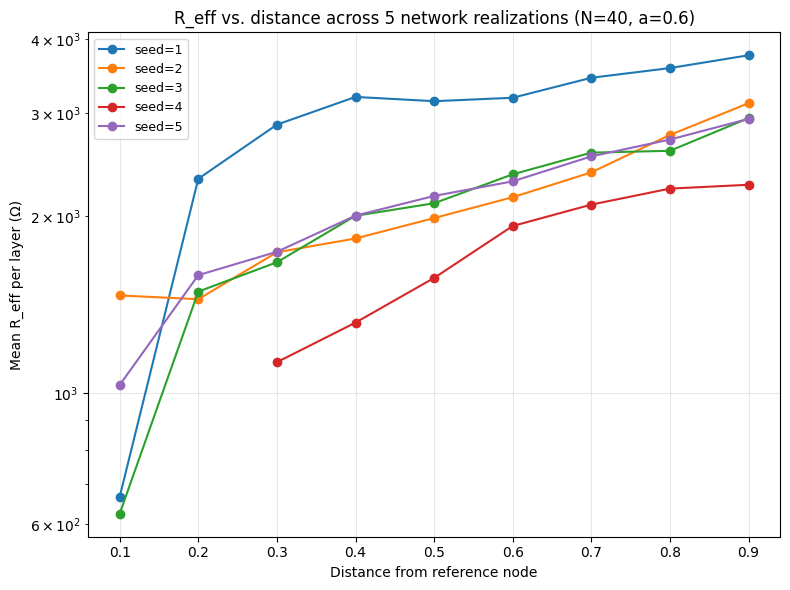

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for seed, layer_means in realization_curves.items():
    ds = sorted(layer_means)
    ax.plot(ds, [layer_means[d] for d in ds], marker='o', label=f'seed={seed}')
ax.set_yscale('log')
ax.set_xlabel('Distance from reference node')
ax.set_ylabel('Mean R_eff per layer (Ω)')
ax.set_title(f'R_eff vs. distance across {len(seeds)} network realizations (N={N}, a={a})')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
exp_manager.save_figure(fig, 'realizations_overlay.png')
plt.show()

---
## 8. Point probe vs. whole-face resistance

Merging an entire source/drain face into one terminal (`merge_boundary_nodes`,
used everywhere else in this project) opens up many more parallel current
paths than a single point probe does. So probing one source-face node
against one drain-face node should always read a **higher** R_eff than the
whole-face merged value, across every realization from section 7.

In [17]:
print(f"{'seed':>6} | {'whole-face R_eff':>18} | {'point-probe R_eff':>18} | ratio")
print("-" * 62)
for seed in seeds:
    res_s, _ = generate_percolating_network(N, a, k_uniform=k, seed=seed)
    inter_s = res_s['pre_merge_intersections']
    seg_s = res_s['pre_merge_segment_to_nodes']
    graph_s = build_graph_from_segments(len(inter_s), seg_s)
    i0 = res_s['pre_merge_source_nodes'][0]
    j0 = res_s['pre_merge_drain_nodes'][0]

    point_r = measure_r_eff(inter_s, graph_s, seg_s, i0, j0, k=k)['impedance']
    whole_face_r = res_s['impedance']
    ratio = point_r / whole_face_r if whole_face_r > 0 else float('nan')
    print(f"{seed:>6} | {whole_face_r:>18.4f} | {point_r:>18.4f} | {ratio:>5.2f}x")
    assert point_r >= whole_face_r, f"seed={seed}: point probe R_eff should not be below the whole-face R_eff"

print("\nPASSED: point probe R_eff >= whole-face R_eff in every realization, as expected")

  seed |   whole-face R_eff |  point-probe R_eff | ratio
--------------------------------------------------------------
     1 |          3836.6406 |          3910.9405 |  1.02x
     2 |          2664.0160 |          3221.0933 |  1.21x
     3 |          3358.3588 |          3437.4519 |  1.02x
     4 |          1932.7590 |          2560.5388 |  1.32x
     5 |          1856.6366 |          3449.4615 |  1.86x

PASSED: point probe R_eff >= whole-face R_eff in every realization, as expected


---
## Save experiment summary

In [18]:
summary = {
    'network_params': {'N': N, 'a': a, 'k': k},
    'validation': 'PASSED (ring + ladder closed-form checks)',
    'manual_probes': exp2_records,
    'onion_protocol': {
        'reference_node': reference_node,
        'layer_distances': layer_distances,
        'n_probes': len(records),
    },
    'realizations': {str(seed): layer_means for seed, layer_means in realization_curves.items()},
}
exp_manager.save_json(summary, 'experiment_summary.json')

  [OK] JSON saved: experiment_summary.json
  [WARNING] PDF auto-generation failed: No module named 'reportlab'


'/content/drive/MyDrive/ColabProject/experiments/exp_841/experiment_summary.json'